In [1]:
import torch
import sys

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert torch.cuda.is_available(), "Please enable GPU runtime."

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
import ultralytics

from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)

ultralytics.checks()

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [3]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/FridgeML")
ZIP_PATH = DRIVE_ROOT / "fridge_layers_v1.zip"

DATASET_ROOT = Path("/content/fridge_dataset")
RUNS_ROOT = DRIVE_ROOT / "runs"

RUNS_ROOT.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.exists(), f"Dataset not found: {ZIP_PATH}"

print("Dataset ZIP:", ZIP_PATH)
print("Training output:", RUNS_ROOT)

Dataset ZIP: /content/drive/MyDrive/FridgeML/fridge_layers_v1.zip
Training output: /content/drive/MyDrive/FridgeML/runs


In [5]:
import zipfile

DATASET_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATASET_ROOT)

print("Dataset extracted successfully.")

for path in DATASET_ROOT.iterdir():
    print(path.name)

Dataset extracted successfully.
README.roboflow.txt
valid
train
data.yaml
test


In [6]:
yaml_files = list(DATASET_ROOT.rglob("data.yaml"))

assert len(yaml_files) == 1, "Expected exactly one data.yaml"

DATA_YAML = yaml_files[0]
DATASET_DIR = DATA_YAML.parent

print("Dataset directory:", DATASET_DIR)
print(DATA_YAML.read_text())

Dataset directory: /content/fridge_dataset
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['layers']

roboflow:
  workspace: jingjings-workspace-tifdr
  project: refrigeratorlayers
  version: 1
  license: Private
  url: https://app.roboflow.com/jingjings-workspace-tifdr/refrigeratorlayers/1


In [7]:
import yaml

with DATA_YAML.open("r") as file:
    config = yaml.safe_load(file)

print("Original configuration:")
print(config)

Original configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['layers'], 'roboflow': {'workspace': 'jingjings-workspace-tifdr', 'project': 'refrigeratorlayers', 'version': 1, 'license': 'Private', 'url': 'https://app.roboflow.com/jingjings-workspace-tifdr/refrigeratorlayers/1'}}


In [8]:
names = config["names"]

if isinstance(names, dict):
    names = list(names.values())

assert names == ["layers"], (
    f"Expected one class named layers, got {names}"
)

val_folder = (
    "valid" if (DATASET_DIR / "valid").exists()
    else "val"
)

dataset_config = {
    "path": str(DATASET_DIR),
    "train": "train/images",
    "val": f"{val_folder}/images",
    "nc": 1,
    "names": {0: "layers"},
}

if (DATASET_DIR / "test/images").exists():
    dataset_config["test"] = "test/images"

TRAIN_YAML = DATASET_DIR / "train_config.yaml"

with TRAIN_YAML.open("w") as file:
    yaml.safe_dump(dataset_config, file, sort_keys=False)

print(TRAIN_YAML.read_text())

path: /content/fridge_dataset
train: train/images
val: valid/images
nc: 1
names:
  0: layers
test: test/images



In [9]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

splits = ["train", val_folder]

if "test" in dataset_config:
    splits.append("test")

dataset_summary = {}

for split in splits:

    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"

    images = sorted(
        p for p in image_dir.iterdir()
        if p.suffix.lower() in IMAGE_EXTENSIONS
    )

    labels = list(label_dir.glob("*.txt"))

    assert images, f"No images in {split}"

    box_count = 0

    for image_path in images:

        label_path = label_dir / f"{image_path.stem}.txt"

        assert label_path.exists(), (
            f"Missing label: {image_path.name}"
        )

        lines = label_path.read_text().splitlines()

        assert lines, f"No layers in {label_path.name}"

        for line in lines:

            values = line.split()

            assert len(values) == 5
            assert int(values[0]) == 0

            x, y, w, h = map(float, values[1:])

            assert 0 <= x <= 1
            assert 0 <= y <= 1
            assert 0 < w <= 1
            assert 0 < h <= 1

            eps = 1e-4

            assert x - w / 2 >= -eps
            assert y - h / 2 >= -eps
            assert x + w / 2 <= 1 + eps
            assert y + h / 2 <= 1 + eps

            box_count += 1

    dataset_summary[split] = {
        "images": len(images),
        "labels": len(labels),
        "boxes": box_count,
    }

    print(
        f"{split}: {len(images)} images, "
        f"{len(labels)} labels, {box_count} boxes"
    )

train: 35 images, 35 labels, 161 boxes
valid: 10 images, 10 labels, 44 boxes
test: 5 images, 5 labels, 21 boxes


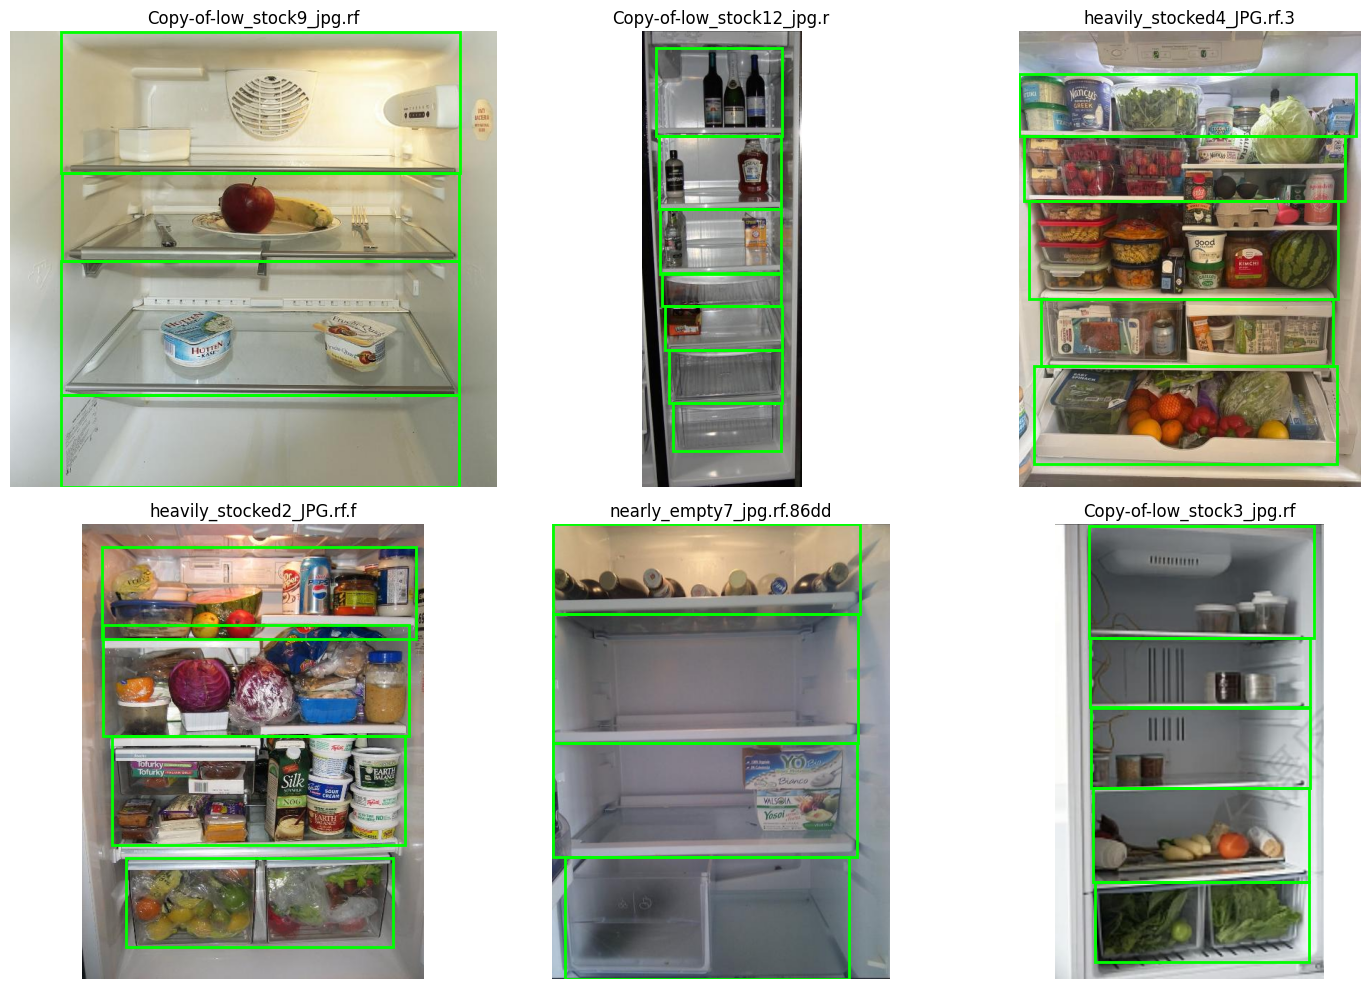

In [10]:
import random

import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle

random.seed(42)

train_images = sorted(
    p for p in (DATASET_DIR / "train/images").iterdir()
    if p.suffix.lower() in IMAGE_EXTENSIONS
)

samples = random.sample(
    train_images,
    min(6, len(train_images))
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax in axes.flat:
    ax.axis("off")

for ax, image_path in zip(axes.flat, samples):

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    label_path = (
        DATASET_DIR
        / "train/labels"
        / f"{image_path.stem}.txt"
    )

    ax.imshow(image)

    for line in label_path.read_text().splitlines():

        _, x, y, w, h = map(float, line.split())

        x1 = (x - w / 2) * width
        y1 = (y - h / 2) * height

        rect = Rectangle(
            (x1, y1),
            w * width,
            h * height,
            linewidth=2,
            edgecolor="lime",
            facecolor="none",
        )

        ax.add_patch(rect)

    ax.set_title(image_path.name[:25])

plt.tight_layout()
plt.show()

In [11]:
model = YOLO("yolo11n.pt")

model.info()

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


(181, 2624080, 0, 6.6733184)

In [12]:
train_results = model.train(
    data=str(TRAIN_YAML),

    # Basic training settings
    epochs=100,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,

    # Reproducibility and early stopping
    seed=42,
    patience=20,
    deterministic=True,

    # Data augmentation
    degrees=5.0,
    translate=0.05,
    scale=0.1,
    fliplr=0.5,
    flipud=0.0,
    mosaic=0.0,
    mixup=0.0,

    # Output settings
    project=str(RUNS_ROOT),
    name="fridge_layers_v1",
    exist_ok=False,
    plots=True,
    save=True,
    save_period=10,
)

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fridge_dataset/train_config.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=fridge_layers_v1, nbs=64, nms=None, opset=None

In [13]:
RUN_DIR = Path(model.trainer.save_dir)

BEST_WEIGHTS = RUN_DIR / "weights/best.pt"
LAST_WEIGHTS = RUN_DIR / "weights/last.pt"

assert BEST_WEIGHTS.exists()

print("Training directory:", RUN_DIR)
print("Best model:", BEST_WEIGHTS)
print("Last model:", LAST_WEIGHTS)

for path in RUN_DIR.iterdir():
    print(path.name)

Training directory: /content/drive/MyDrive/FridgeML/runs/fridge_layers_v1
Best model: /content/drive/MyDrive/FridgeML/runs/fridge_layers_v1/weights/best.pt
Last model: /content/drive/MyDrive/FridgeML/runs/fridge_layers_v1/weights/last.pt
weights
args.yaml
labels.jpg
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
results.csv
train_batch450.jpg
train_batch451.jpg
train_batch452.jpg
BoxPR_curve.png
val_batch0_labels.jpg
val_batch0_pred.jpg
BoxF1_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix_normalized.png
confusion_matrix.png
results.png


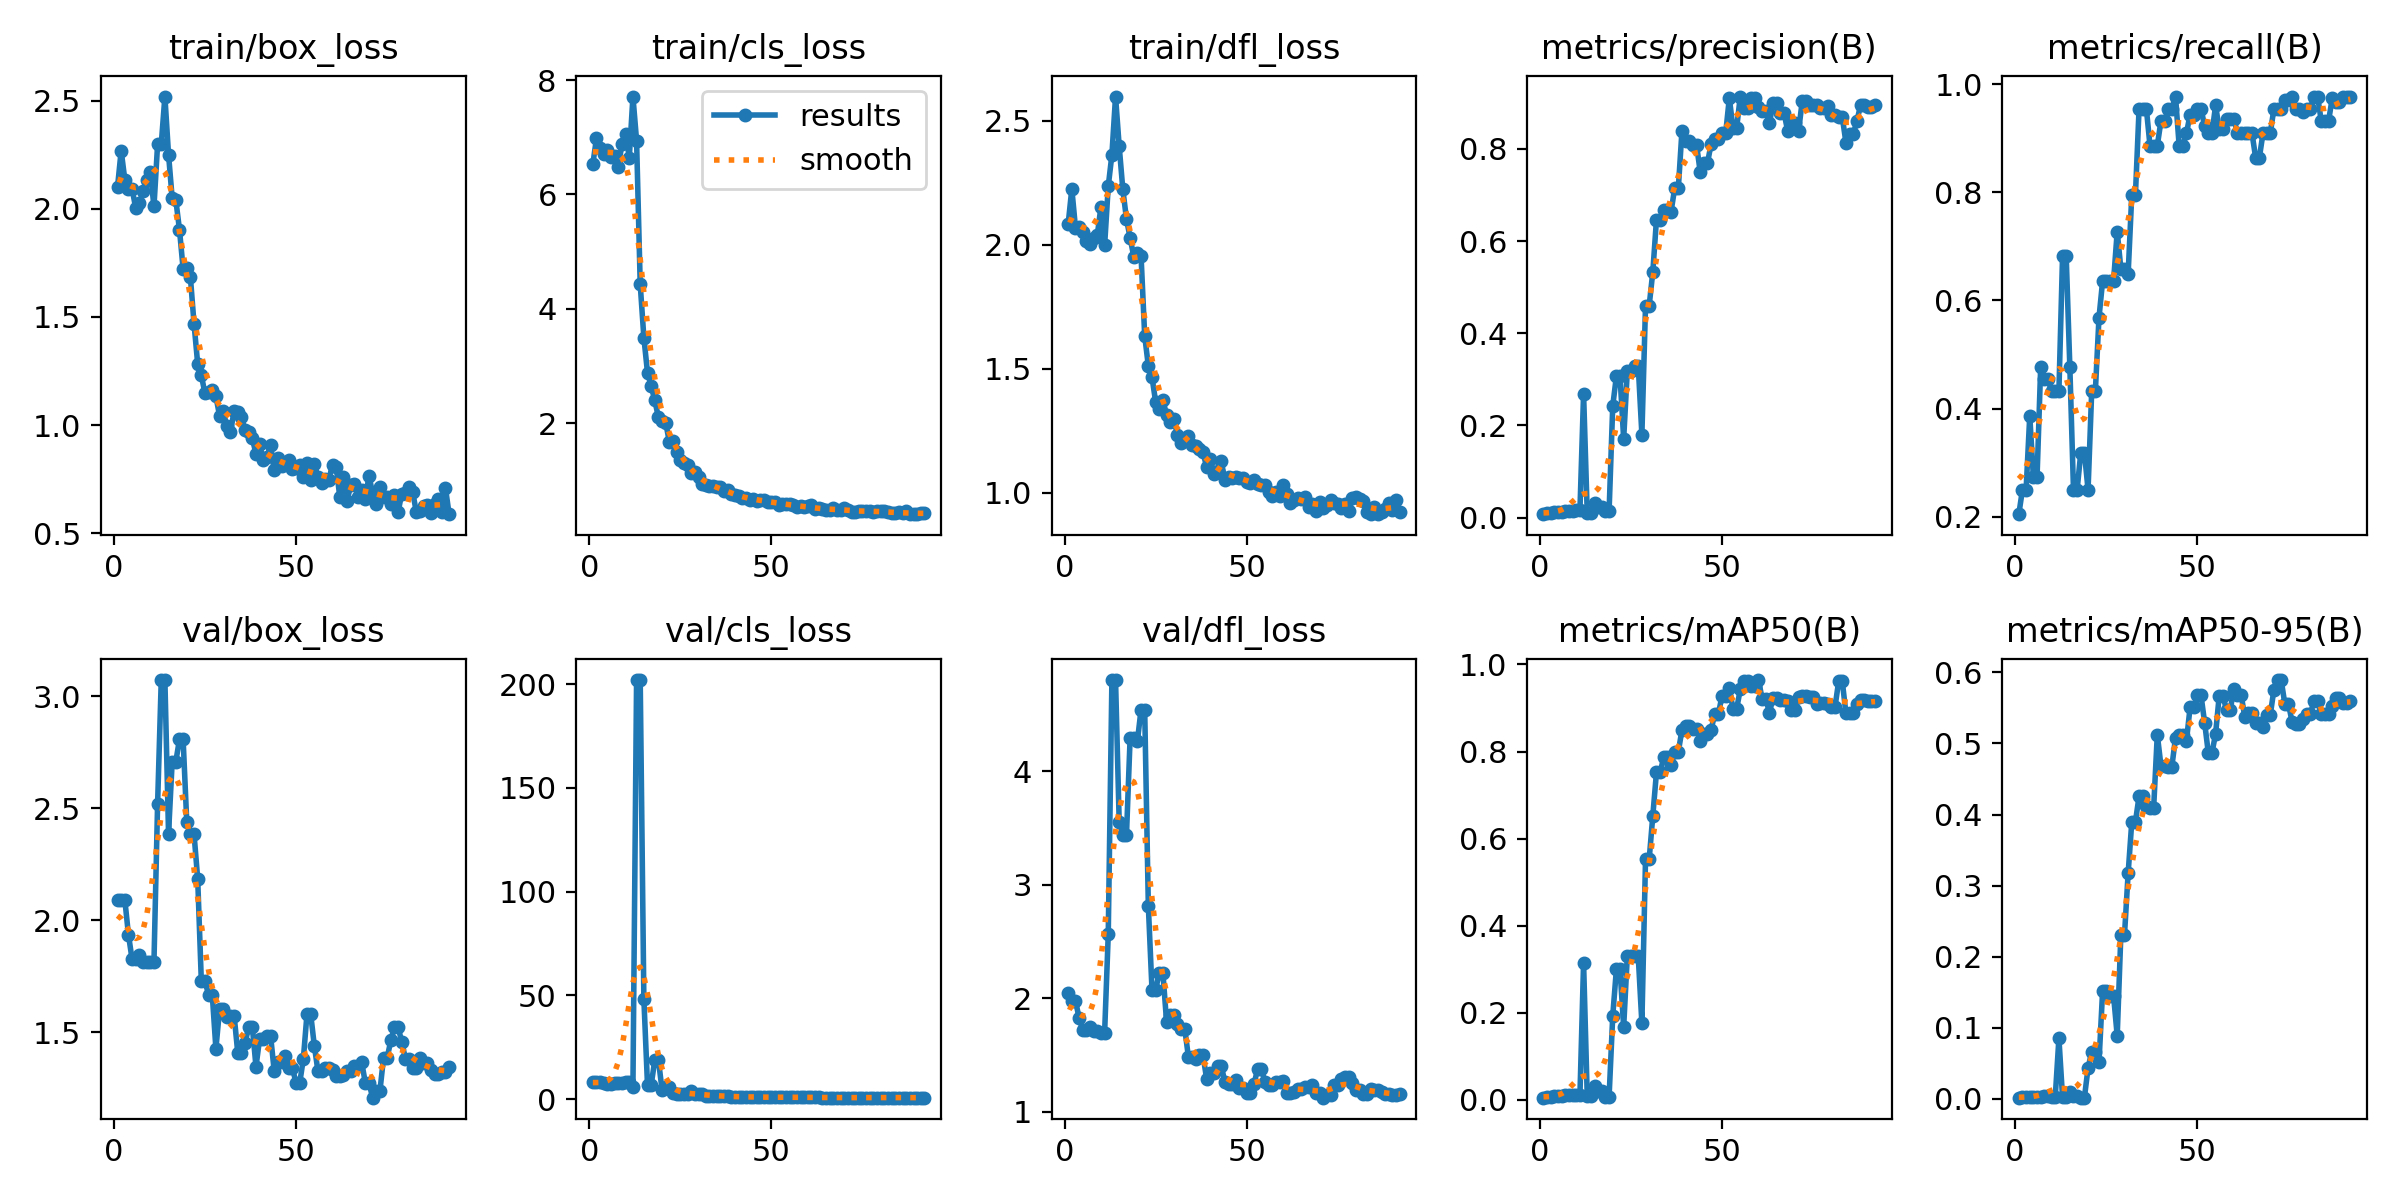

In [14]:
from IPython.display import display
from PIL import Image

result_plot = RUN_DIR / "results.png"

if result_plot.exists():
    display(Image.open(result_plot))

In [15]:
import pandas as pd

history = pd.read_csv(RUN_DIR / "results.csv")

history.columns = history.columns.str.strip()

display(history.tail())

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
87,88,116.631,0.63540,0.40637,0.93439,0.89481,0.96677,0.91774,0.56408,1.31360,0.73498,1.15641,0.000277,0.000277,0.000277
88,89,117.623,0.65614,0.40978,0.96067,0.89481,0.96677,0.91774,0.56408,1.31360,0.73498,1.15641,0.000258,0.000258,0.000258
89,90,118.684,0.59880,0.41797,0.93131,0.89003,0.97727,0.91540,0.55712,1.32007,0.73055,1.14558,0.000238,0.000238,0.000238
90,91,120.901,0.70796,0.42662,0.97296,0.89003,0.97727,0.91540,0.55712,1.32007,0.73055,1.14558,0.000218,0.000218,0.000218
91,92,122.416,0.58741,0.41955,0.92095,0.89570,0.97586,0.91594,0.56044,1.34233,0.73187,1.15514,0.000198,0.000198,0.000198


In [16]:
metric_column = "metrics/mAP50-95(B)"

if metric_column in history.columns:

    best_row = history.loc[
        history[metric_column].idxmax()
    ]

    print("Highest mAP50-95 epoch:", best_row["epoch"])
    print("Highest mAP50-95:", best_row[metric_column])

Highest mAP50-95 epoch: 72.0
Highest mAP50-95: 0.58924


In [17]:
best_model = YOLO(str(BEST_WEIGHTS))

val_metrics = best_model.val(
    data=str(TRAIN_YAML),
    split="val",
    imgsz=640,
    device=0,
    plots=True,
    project=str(RUN_DIR),
    name="validation_evaluation",
)

print("Precision:", val_metrics.box.mp)
print("Recall:", val_metrics.box.mr)
print("mAP50:", val_metrics.box.map50)
print("mAP50-95:", val_metrics.box.map)

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1252.9±364.0 MB/s, size: 44.4 KB)
val: Scanning /content/fridge_dataset/valid/labels.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 2.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 8.1it/s 0.1s
                   all         10         44      0.904      0.955      0.928      0.589
Speed: 0.4ms preprocess, 4.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/MyDrive/FridgeML/runs/fridge_layers_v1/validation_evaluation
Precision: 0.9038585616528296
Recall: 0.9545454545454546
mAP50: 0.9277107699541709
mAP50-95: 0.588913275749713


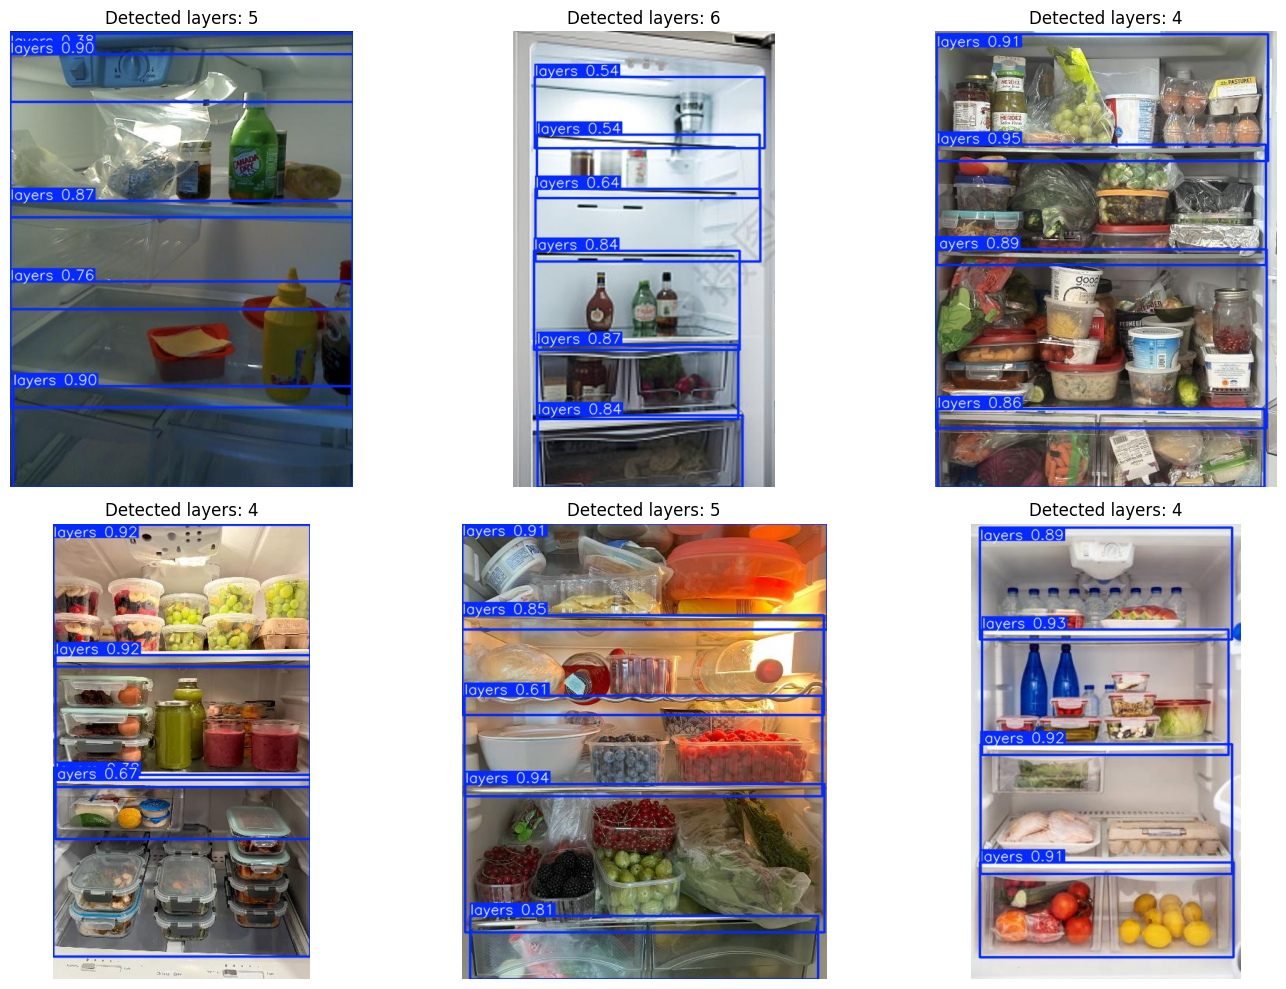

In [18]:
val_results = best_model.predict(
    source=str(
        DATASET_DIR / val_folder / "images"
    ),
    conf=0.25,
    imgsz=640,
    device=0,
    verbose=False,
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax in axes.flat:
    ax.axis("off")

for ax, result in zip(axes.flat, val_results[:6]):

    annotated = result.plot()

    # Ultralytics returns a BGR image.
    ax.imshow(annotated[:, :, ::-1])

    ax.set_title(
        f"Detected layers: {len(result.boxes)}"
    )

plt.tight_layout()
plt.show()

In [19]:
import json

if "test" in dataset_config:

    test_metrics = best_model.val(
        data=str(TRAIN_YAML),
        split="test",
        imgsz=640,
        device=0,
        plots=True,
        project=str(RUN_DIR),
        name="test_evaluation",
    )

    test_summary = {
        "precision": float(test_metrics.box.mp),
        "recall": float(test_metrics.box.mr),
        "mAP50": float(test_metrics.box.map50),
        "mAP50-95": float(test_metrics.box.map),
    }

    print(json.dumps(test_summary, indent=2))

    (RUN_DIR / "test_metrics.json").write_text(
        json.dumps(test_summary, indent=2)
    )

else:
    print("No independent test dataset available.")

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1158.3±377.4 MB/s, size: 30.9 KB)
val: Scanning /content/fridge_dataset/test/labels... 5 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 5/5 1.5Kit/s 0.0s
val: New cache created: /content/fridge_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 12.5it/s 0.1s
                   all          5         21       0.99          1          1      0.628
Speed: 0.4ms preprocess, 6.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/drive/MyDrive/FridgeML/runs/fridge_layers_v1/test_evaluation
{
  "precision": 0.989928503873417,
  "recall": 1.0,
  "mAP50": 1.0,
  "mAP50-95": 0.6275456831397426
}



image 1/5 /content/fridge_dataset/test/images/Copy-of-low_stock1_jpg.rf.0c72fa19288b601d94d0a6007f281f5d.jpg: 640x448 6 layerss, 10.8ms
image 2/5 /content/fridge_dataset/test/images/Copy-of-low_stock5_jpg.rf.71017dcebaa780ee336bb630c540f6ba.jpg: 640x544 5 layerss, 24.3ms
image 3/5 /content/fridge_dataset/test/images/empty2_jpg.rf.144aa5ca946d1da46b80b553842aad8a.jpg: 640x544 4 layerss, 11.0ms
image 4/5 /content/fridge_dataset/test/images/heavily_stocked10_JPG.rf.7c30d7c2d6aa34d5d1cc8b47dcefe49e.jpg: 640x384 5 layerss, 10.5ms
image 5/5 /content/fridge_dataset/test/images/moderate_stock8_png.rf.d9f25ca2e93a0a9603e4b5c309aaeb00.jpg: 640x384 5 layerss, 10.6ms
Speed: 2.3ms preprocess, 13.4ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 384)
Results saved to /content/drive/MyDrive/FridgeML/runs/fridge_layers_v1/test_predictions
5 labels saved to /content/drive/MyDrive/FridgeML/runs/fridge_layers_v1/test_predictions/labels
Copy-of-low_stock1_jpg.rf.0c72fa19288b601d94d0a6007f28

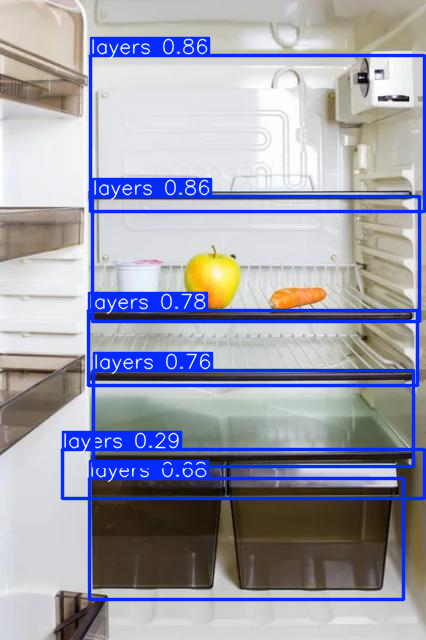

Copy-of-low_stock5_jpg.rf.71017dcebaa780ee336bb630c540f6ba.jpg Layers detected: 5


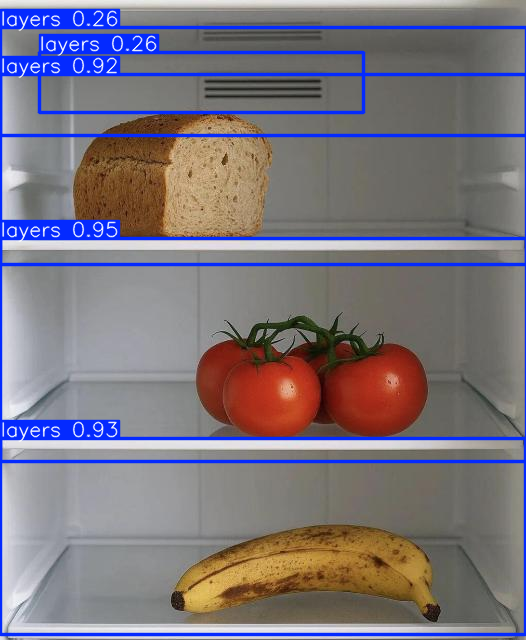

empty2_jpg.rf.144aa5ca946d1da46b80b553842aad8a.jpg Layers detected: 4


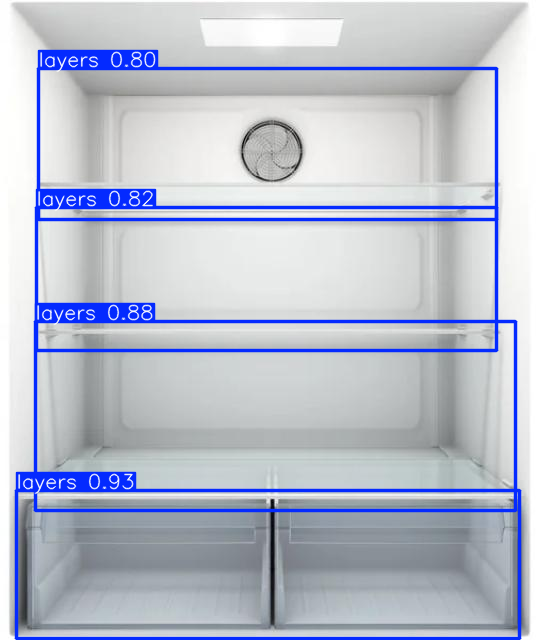

heavily_stocked10_JPG.rf.7c30d7c2d6aa34d5d1cc8b47dcefe49e.jpg Layers detected: 5


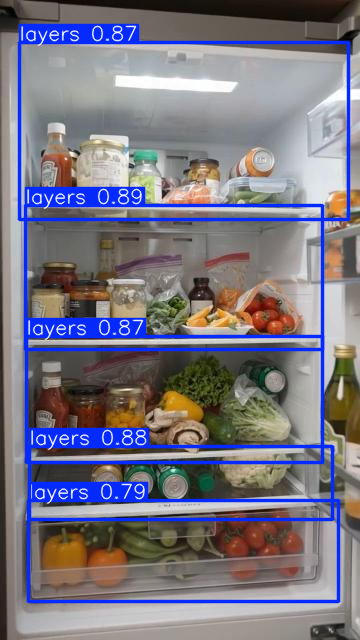

moderate_stock8_png.rf.d9f25ca2e93a0a9603e4b5c309aaeb00.jpg Layers detected: 5


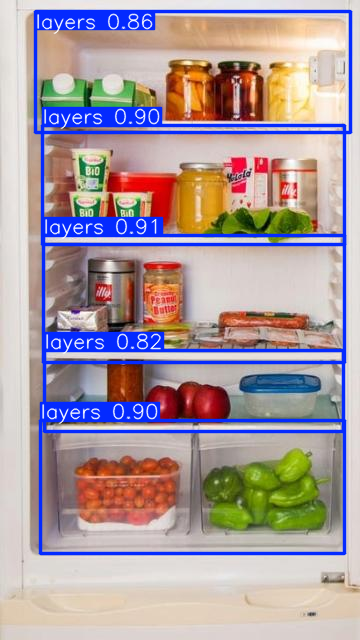

In [20]:
if "test" in dataset_config:

    predictions = best_model.predict(
        source=str(DATASET_DIR / "test/images"),
        conf=0.25,
        imgsz=640,
        device=0,
        save=True,
        save_txt=True,
        save_conf=True,
        project=str(RUN_DIR),
        name="test_predictions",
    )

    for result in predictions:

        print(
            Path(result.path).name,
            "Layers detected:",
            len(result.boxes)
        )

        display(
            Image.fromarray(
                result.plot()[:, :, ::-1]
            )
        )

In [21]:
import shutil

EXPORT_DIR = DRIVE_ROOT / "export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

DEPLOYMENT_WEIGHTS = EXPORT_DIR / "fridge_layers.pt"

shutil.copy2(
    BEST_WEIGHTS,
    DEPLOYMENT_WEIGHTS
)

print("Model exported:", DEPLOYMENT_WEIGHTS)

print(
    "File size:",
    round(
        DEPLOYMENT_WEIGHTS.stat().st_size / 1024**2,
        2
    ),
    "MB"
)

Model exported: /content/drive/MyDrive/FridgeML/export/fridge_layers.pt
File size: 5.25 MB


In [22]:
import platform

training_files = [
    "args.yaml",
    "results.csv",
    "results.png",
    "confusion_matrix.png",
    "test_metrics.json",
]

for filename in training_files:

    source = RUN_DIR / filename

    if source.exists():

        shutil.copy2(
            source,
            EXPORT_DIR / filename
        )

# Save the original dataset configuration.
shutil.copy2(
    DATA_YAML,
    EXPORT_DIR / "data.yaml"
)

environment = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "ultralytics": ultralytics.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "dataset": ZIP_PATH.name,
    "dataset_summary": dataset_summary,
}

(EXPORT_DIR / "environment.json").write_text(
    json.dumps(environment, indent=2)
)

print("Exported files:")

for path in EXPORT_DIR.iterdir():
    print(path.name)

Exported files:
fridge_layers.pt
args.yaml
results.csv
results.png
confusion_matrix.png
test_metrics.json
data.yaml
environment.json


In [23]:
from google.colab import files

archive = shutil.make_archive(
    "/content/fridge_training_artifacts",
    "zip",
    root_dir=EXPORT_DIR,
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>